# Team Bordeaux: audited results

This notebook reads saved results. It never fits a model or opens test descriptions. See [the full analysis handoff](analysis_results/README.md) and [label audit](analysis_results/LABEL_AUDIT.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
RESULTS = Path('analysis_results')
lock = json.loads((RESULTS / 'selection_lock.json').read_text())
final = json.loads((RESULTS / 'final_metrics.json').read_text())
display(Markdown(f"**Selected:** {lock['selected_model']}, {lock['training_rows']:,} training reviews. **Recovered holdout:** {final['metrics']['rows']:,} reviews."))
display(pd.DataFrame([lock['validation_scores'], final['metrics']], index=['validation', 'recovered holdout']))

**Selected:** Linear SVM, 81,141 training reviews. **Recovered holdout:** 2,063 reviews.

,rows,accuracy,balanced_accuracy,macro_f1
validation,27121,0.990598,0.988644,0.989287
recovered holdout,2063,0.992244,0.991124,0.987097


## Population and evaluation limitations

The audit reconstructs prior predictive exposure, excludes exposed wine families, and applies frozen label rules. Whole-data aggregate EDA was previously seen, so the final population is a recovered predictive holdout rather than a pristine external test. Confidence intervals condition on the retained population and fixed trained model.

In [2]:
audit = json.loads((RESULTS / 'audit_summary.json').read_text())
display(pd.Series(audit['saved_test_exposure_counts_nonexclusive'], name='rows; flags overlap').to_frame())
display(pd.read_csv(RESULTS / 'label_coverage.csv'))

,rows; flags overlap
saved_train,0
saved_validation,0
eda_train,20243
eda_validation,5683
original_model12_train,23
original_model12_validation,24
normalized_text_exposed,25936
wine_family_exposed,29941
saved_test,33836
candidate_predictive_holdout,5679


,partition,color,retained,rows
0,train,dessert,False,872
1,train,red,False,7627
2,train,red,True,54664
3,train,rose,False,2471
4,train,sparkling,False,3322
5,train,white,False,6071
6,train,white,True,26479
7,validation,dessert,False,291
8,validation,red,False,2483
9,validation,red,True,18281


## Model progression and geographic transfer

Compare stages with matching validation populations. The geographic experiment fixes training size and class mix; it does not isolate geography from every other population difference.

,stage,model,split,rows,accuracy,balanced_accuracy,macro_f1
0,narrow_10,Majority baseline,training,10,0.5000,0.5000,0.3333
1,narrow_10,Majority baseline,validation,2886,0.5374,0.5000,0.3496
2,narrow_10,Naive Bayes,training,10,1.0000,1.0000,1.0000
3,narrow_10,Naive Bayes,validation,2886,0.7606,0.7598,0.7595
4,narrow_10,Logistic regression,training,10,1.0000,1.0000,1.0000
...,...,...,...,...,...,...,...
59,allregion_full,Naive Bayes,validation,27121,0.9864,0.9821,0.9845
60,allregion_full,Logistic regression,training,81141,0.9934,0.9912,0.9925
61,allregion_full,Logistic regression,validation,27121,0.9900,0.9869,0.9886
62,allregion_full,Linear SVM,training,81141,0.9990,0.9988,0.9988


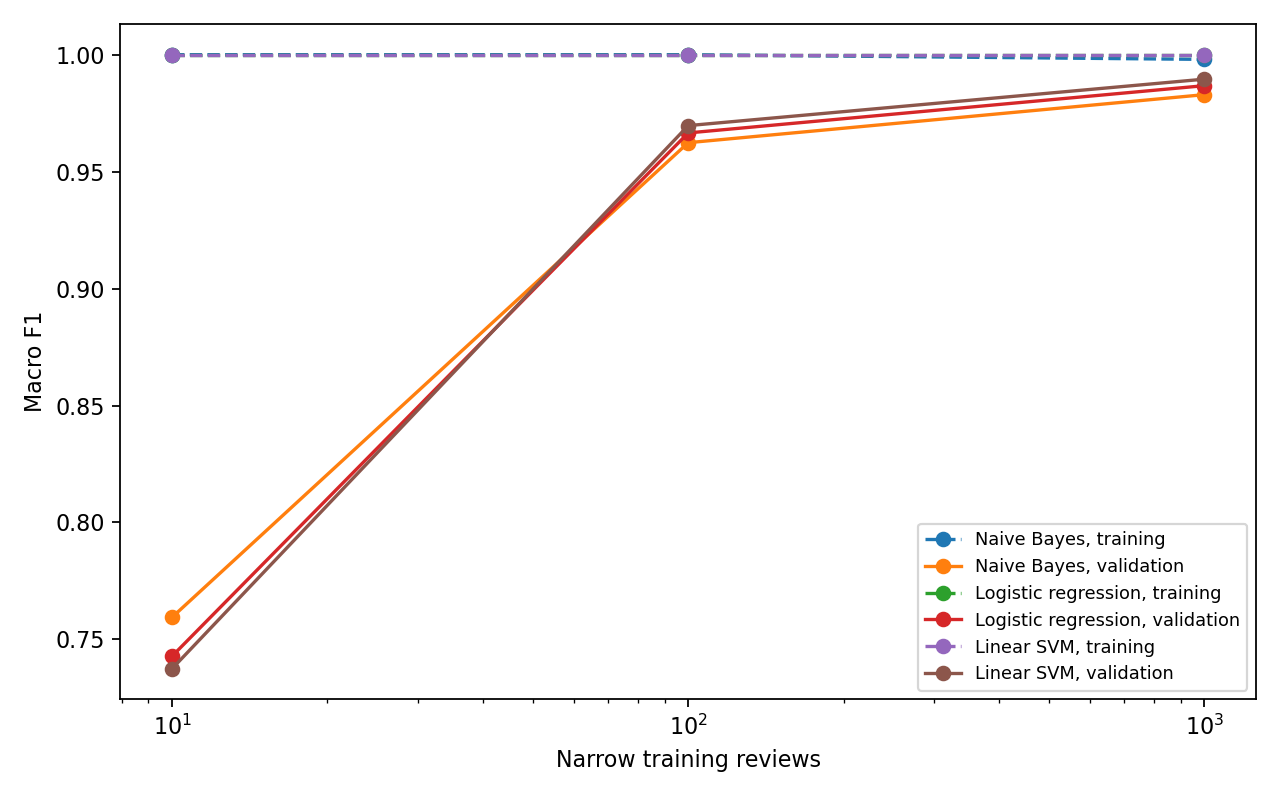

,stage,model,group,rows,accuracy,balanced_accuracy,macro_f1
6,california_20000_global,Linear SVM,California,8742,0.9928,0.9896,0.9909
7,california_20000_global,Linear SVM,Outside California,18379,0.9678,0.9593,0.9643
14,allregion_20000,Linear SVM,California,8742,0.9920,0.9889,0.9899
15,allregion_20000,Linear SVM,Outside California,18379,0.9873,0.9854,0.9861
22,allregion_full,Linear SVM,California,8742,0.9925,0.9896,0.9905
23,allregion_full,Linear SVM,Outside California,18379,0.9897,0.9882,0.9887


,stage,model,split,rows,accuracy,balanced_accuracy,macro_f1
0,legacy_full_size,Naive Bayes,training,94839,0.9833,0.9805,0.9814
1,legacy_full_size,Naive Bayes,validation,31614,0.9822,0.9792,0.9802
2,legacy_full_size,Logistic regression,training,94839,0.9895,0.9879,0.9884
3,legacy_full_size,Logistic regression,validation,31614,0.9863,0.9840,0.9848
4,legacy_full_size,Linear SVM,training,94839,0.9974,0.9973,0.9971
5,legacy_full_size,Linear SVM,validation,31614,0.9873,0.9859,0.9859


In [3]:
comparison = pd.read_csv(RESULTS / 'audited_model_comparison.csv')
display(comparison.round(4))
display(Image(filename=str(RESULTS / 'learning_curve.png')))
regions = pd.read_csv(RESULTS / 'regional_validation.csv')
display(regions[regions['model'].eq('Linear SVM')].round(4))
display(pd.read_csv(RESULTS / 'original_full_size_comparison.csv').round(4))

## Distinctive and shared review language

Coefficients are associations, not causal effects. Shared words occur frequently in both classes. All word-frequency summaries use training data.

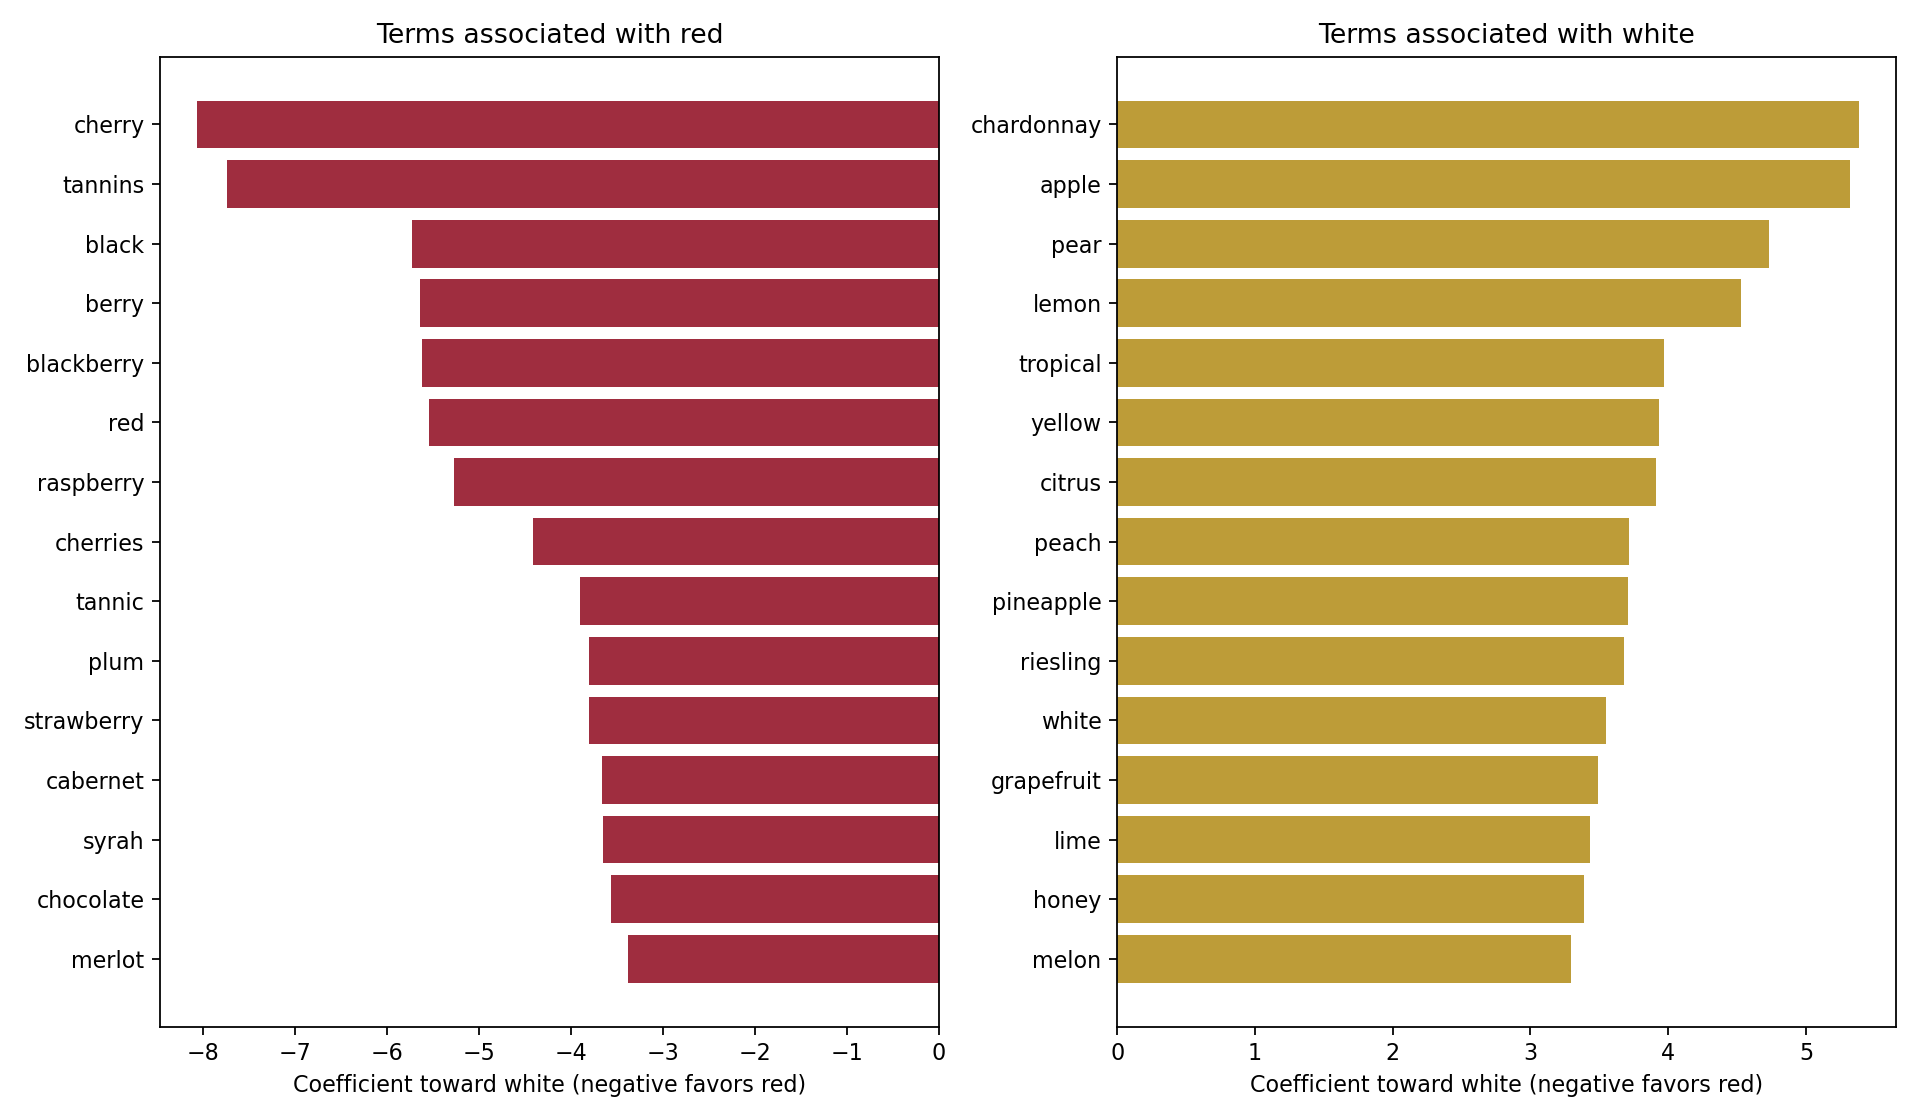

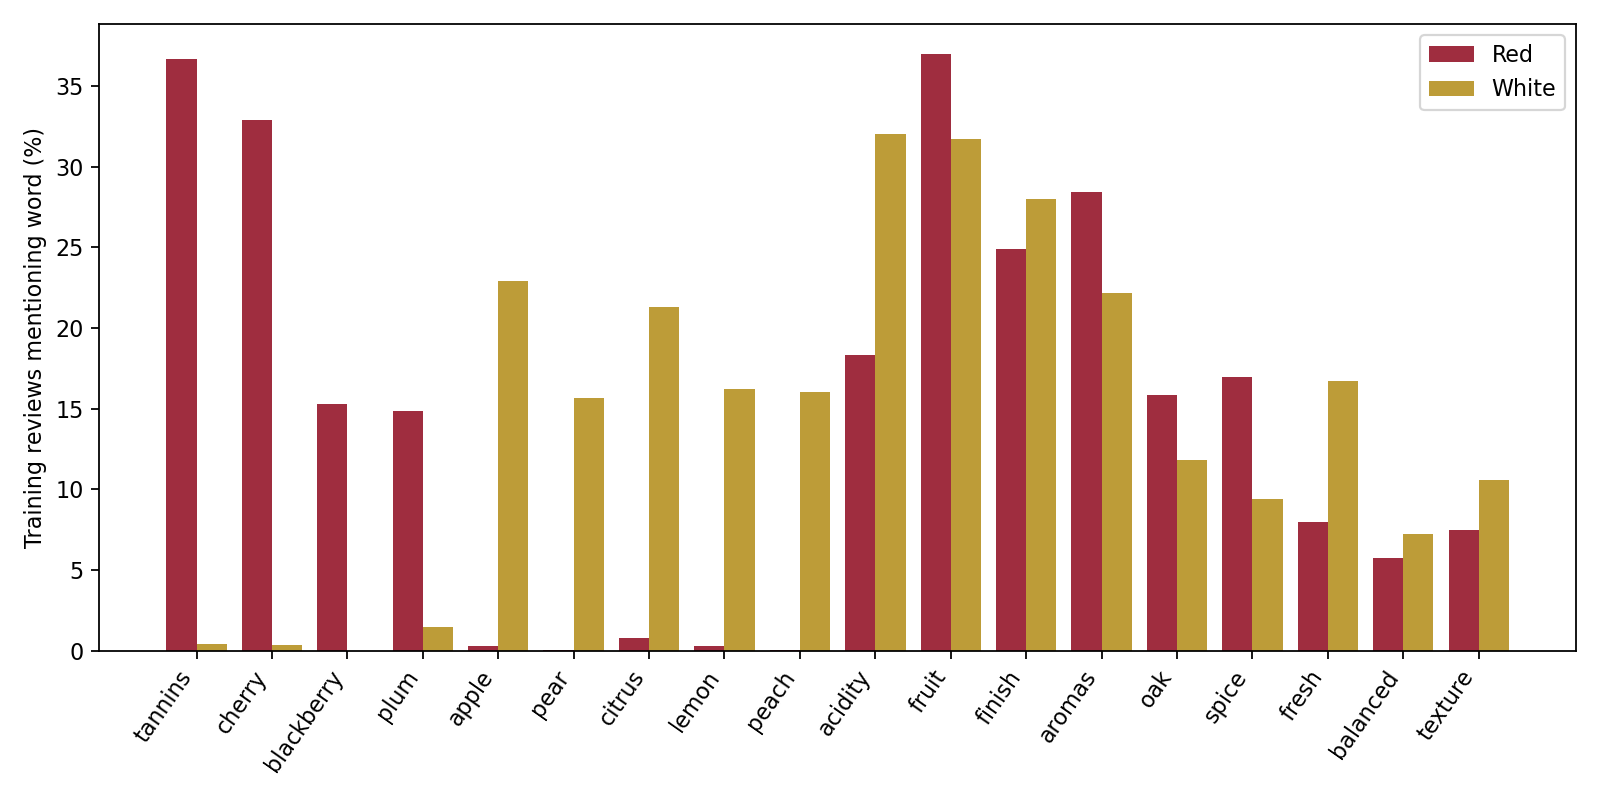

,term,red_pct,white_pct,minimum_class_pct,prevalence_ratio_white_red
0,wine,49.79,48.75,48.75,0.98
1,flavors,47.00,51.50,47.00,1.10
2,fruit,37.00,31.73,31.73,0.86
3,finish,24.87,28.01,24.87,1.13
4,palate,24.31,25.44,24.31,1.05
5,aromas,28.46,22.16,22.16,0.78
6,ripe,19.25,19.28,19.25,1.00
7,drink,22.10,18.72,18.72,0.85
8,acidity,18.30,32.05,18.30,1.75
9,rich,13.54,13.45,13.45,0.99


,rows,accuracy,balanced_accuracy,macro_f1
unmasked,27121,0.9906,0.9886,0.9893
masked,27121,0.9854,0.9824,0.9834


In [4]:
display(Image(filename=str(RESULTS / 'language_coefficients.png')))
display(Image(filename=str(RESULTS / 'sensory_language.png')))
display(pd.read_csv(RESULTS / 'shared_language_training.csv').head(20).round(2))
masking = json.loads((RESULTS / 'masking_experiment.json').read_text())
display(pd.DataFrame([masking['unmasked'], masking['masked']], index=['unmasked', 'masked']).round(4))

## Validation error inspection

These are development errors, not final test examples. A model error can reflect overlapping language or an imperfect proxy label; it is not sufficient evidence to change a label.

In [5]:
examples = pd.read_csv(RESULTS / 'validation_error_examples.csv')
with pd.option_context('display.max_colwidth', 160):
    display(examples[['row_id','color','predicted_color','variety','description','decision_margin_for_white']])

,row_id,color,predicted_color,variety,description,decision_margin_for_white
0,20818,red,white,Red Blend,"Made overtly sweet, in the style of some Rosenblum wines, the Viognier, Chardonnay, Sauvignon Blanc and Marsanne blend has sugary flavors of pineapples, pea...",3.649098
1,161341,white,red,Pinot Grigio,"This is a heavy, soft, jammy wine that's sweet in raspberry- and strawberry-jam flavors.",-3.181580
2,24016,red,white,Red Blend,"Mainly Chardonnay (with up to 5% Sauvignon Blanc) from several vineyards in Barbaresco and Serralunga, fermented in stainless, then matured in oak. The resu...",2.969329
3,116474,red,white,Pinot Noir,"Pale pink in color, this wine by Mike Sinor shows just-cut lemon, a touch of nectarine, gray slate and a lemon-cucumber element on the tart, refreshing nose...",2.337257
4,79844,red,white,Pinot Noir,"This was the first winery to make a truly white Pinot Noir (back in 2004). Produced exclusively from Pommard clones, it's barrel fermented and aged much lik...",2.089578
5,40321,red,white,Grenache,"A lovely, fresh and focused white wine that offers a classy blend of melon, peach, apple, apricot, herb and mineral flavors. These are layered in a complex,...",1.955012
6,10719,red,white,Grenache,"Tastes a little heavy and flowery, with fleshy, pulpy flavors of peaches, apricots and spicy mangoes. Needs more zesty tang to bring structure to the fruit.",1.936060
7,154934,red,white,Pinot Noir,"No longer an oddity, making a white wine out of Pinot Noir creates a most useful alternative to Chardonnay. Apples and white peaches abound, with a full, cr...",1.608348
8,156199,red,white,Grenache,"Fresh for the summer season is this tutti-frutti Navarran Garnacha. Pink in color and pumped up, this tastes of pink grapefruit, nectarine and citrus pith. ...",1.537518
9,96252,white,red,Sauvignon Blanc,"A first for K Vintners, this fruit was sourced from the Sunset and Evergreen vineyards, and supervised by winemaker, Brennon Leighton. Cool climate characte...",-1.335750


## Locked final evaluation

The selected saved pipeline was evaluated once. Reading this table does not call it again. The bootstrap intervals do not cover label uncertainty or all possible wine-family dependence.

,precision,recall,f1-score,support
red,0.9976,0.9929,0.9952,1687.0000
white,0.9688,0.9894,0.9789,376.0000
accuracy,0.9922,0.9922,0.9922,0.9922
macro avg,0.9832,0.9911,0.9871,2063.0000
weighted avg,0.9924,0.9922,0.9923,2063.0000


,low,high
accuracy,0.9884,0.9956
balanced_accuracy,0.9851,0.9960
macro_f1,0.9804,0.9929


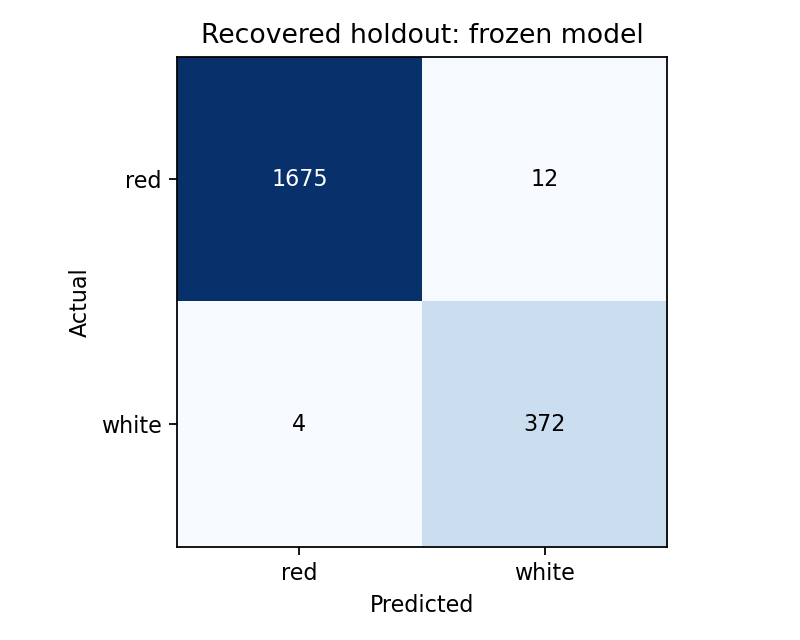

,stage,model,group,rows,accuracy,balanced_accuracy,macro_f1
0,allregion_full,Linear SVM,Outside California,1373,0.9898,0.9883,0.9845
1,allregion_full,Linear SVM,California,690,0.9971,0.9983,0.9938


In [6]:
display(pd.DataFrame(final['classification_report']).T.round(4))
display(pd.DataFrame(final['bootstrap_95pct_intervals']).T.round(4))
display(Image(filename=str(RESULTS / 'final_confusion_matrix.png')))
display(pd.read_csv(RESULTS / 'final_regional_metrics.csv').round(4))